In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    roc_auc_score
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.model_selection import RandomizedSearchCV

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

from xgboost import XGBClassifier

# Import dataset

In [4]:
df = pd.read_csv('/content/dataset.csv', delimiter=',')
df.head()

,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,Female,66,110,73,5.88,1.65,70.2,25.75,0,0,0,0,0,No
1,35,Female,60,125,68,5.71,1.47,42.5,19.58,0,0,0,0,0,No
2,62,Female,57,127,74,6.85,1.52,47.0,20.24,0,0,0,0,0,No
3,73,Male,55,193,112,6.28,1.63,57.4,21.72,0,0,0,0,0,No
4,68,Female,71,150,81,5.71,1.42,36.0,17.79,0,0,0,0,0,No


# EDA

In [5]:
df.info() # Udah bersih, ga ada missing value, tipe data udah sesuai

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5288 entries, 0 to 5287
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     5288 non-null   int64  
 1   gender                  5288 non-null   object 
 2   pulse_rate              5288 non-null   int64  
 3   systolic_bp             5288 non-null   int64  
 4   diastolic_bp            5288 non-null   int64  
 5   glucose                 5288 non-null   float64
 6   height                  5288 non-null   float64
 7   weight                  5288 non-null   float64
 8   bmi                     5288 non-null   float64
 9   family_diabetes         5288 non-null   int64  
 10  hypertensive            5288 non-null   int64  
 11  family_hypertension     5288 non-null   int64  
 12  cardiovascular_disease  5288 non-null   int64  
 13  stroke                  5288 non-null   int64  
 14  diabetic                5288 non-null   

In [6]:
duplicates = df.duplicated().sum()

print("Total Duplicate Rows:", duplicates)

if duplicates == 0:
    print("Insight: Tidak ada duplicate data")
else:
    print("Insight: Dataset memiliki duplicate data")

Total Duplicate Rows: 0
Insight: Tidak ada duplicate data


In [7]:
cols = [
    'family_diabetes',
    'hypertensive',
    'family_hypertension',
    'cardiovascular_disease',
    'stroke'
]

df[cols] = df[cols].astype(bool)

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5288 entries, 0 to 5287
Data columns (total 15 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   age                     5288 non-null   int64  
 1   gender                  5288 non-null   object 
 2   pulse_rate              5288 non-null   int64  
 3   systolic_bp             5288 non-null   int64  
 4   diastolic_bp            5288 non-null   int64  
 5   glucose                 5288 non-null   float64
 6   height                  5288 non-null   float64
 7   weight                  5288 non-null   float64
 8   bmi                     5288 non-null   float64
 9   family_diabetes         5288 non-null   bool   
 10  hypertensive            5288 non-null   bool   
 11  family_hypertension     5288 non-null   bool   
 12  cardiovascular_disease  5288 non-null   bool   
 13  stroke                  5288 non-null   bool   
 14  diabetic                5288 non-null   

In [8]:
df.columns # Ga ada yang di drop karena ga ada ID

Index(['age', 'gender', 'pulse_rate', 'systolic_bp', 'diastolic_bp', 'glucose',
       'height', 'weight', 'bmi', 'family_diabetes', 'hypertensive',
       'family_hypertension', 'cardiovascular_disease', 'stroke', 'diabetic'],
      dtype='object')

In [9]:
df.describe()

,age,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi
count,5288.000000,5288.000000,5288.000000,5288.000000,5288.000000,5288.000000,5288.000000,5288.000000
mean,45.745651,76.626135,133.996596,82.229576,7.563922,1.548886,53.644100,22.466581
std,13.422024,12.229319,22.231752,12.479007,2.944381,0.080328,10.076059,8.819898
min,21.000000,5.000000,62.000000,45.000000,0.000000,0.360000,3.000000,1.220000
25%,35.000000,69.000000,119.000000,73.000000,6.000000,1.520000,46.775000,19.620000
50%,45.000000,76.000000,130.000000,81.000000,6.930000,1.550000,53.000000,21.870000
75%,55.000000,84.000000,147.000000,90.000000,8.130000,1.600000,59.900000,24.472500
max,80.000000,133.000000,231.000000,119.000000,33.460000,1.960000,100.700000,574.130000


In [10]:
num_cols = df.select_dtypes(include = 'number').columns
cat_cols = df.select_dtypes(include='object').columns
bool_cols = df.select_dtypes(include='bool').columns

In [11]:
num_cols

Index(['age', 'pulse_rate', 'systolic_bp', 'diastolic_bp', 'glucose', 'height',
       'weight', 'bmi'],
      dtype='object')

In [12]:
cat_cols

Index(['gender', 'diabetic'], dtype='object')

In [13]:
bool_cols

Index(['family_diabetes', 'hypertensive', 'family_hypertension',
       'cardiovascular_disease', 'stroke'],
      dtype='object')

In [14]:
for col in cat_cols:
  print(df[col].value_counts())
  print('----'*30)

gender
Female    3752
Male      1536
Name: count, dtype: int64
------------------------------------------------------------------------------------------------------------------------
diabetic
No     4946
Yes     342
Name: count, dtype: int64
------------------------------------------------------------------------------------------------------------------------


# Check distribution data

/tmp/ipykernel_2846/650341423.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='diabetic', data=df, palette='viridis')


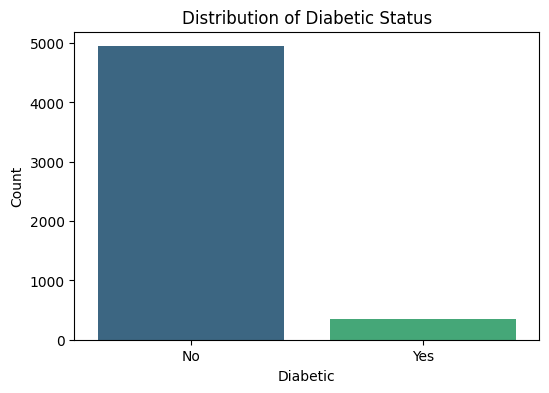

In [15]:
plt.figure(figsize=(6, 4))
sns.countplot(x='diabetic', data=df, palette='viridis')
plt.title('Distribution of Diabetic Status')
plt.xlabel('Diabetic')
plt.ylabel('Count')
plt.show()

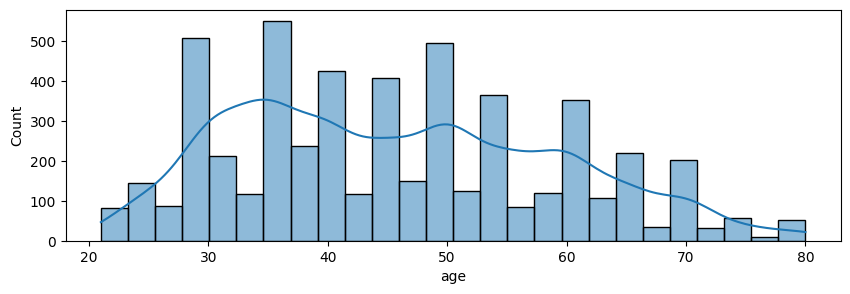

------------------------------------------------------------------------------------------


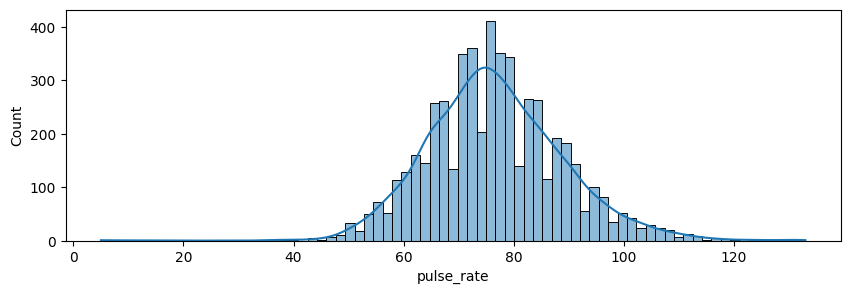

------------------------------------------------------------------------------------------


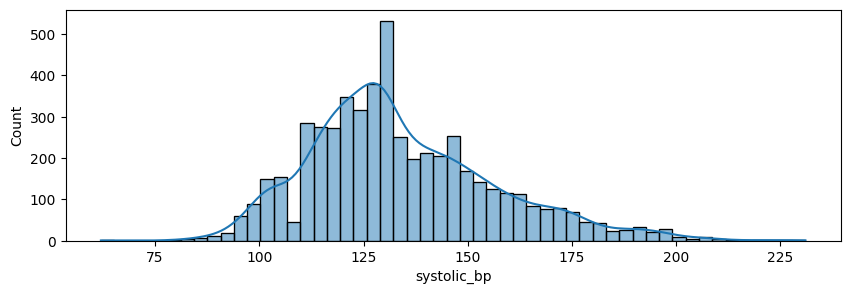

------------------------------------------------------------------------------------------


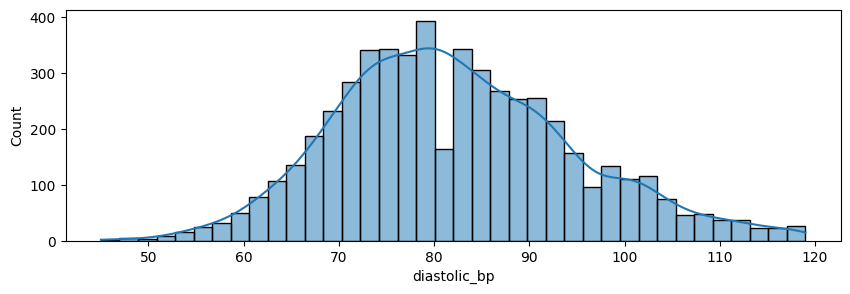

------------------------------------------------------------------------------------------


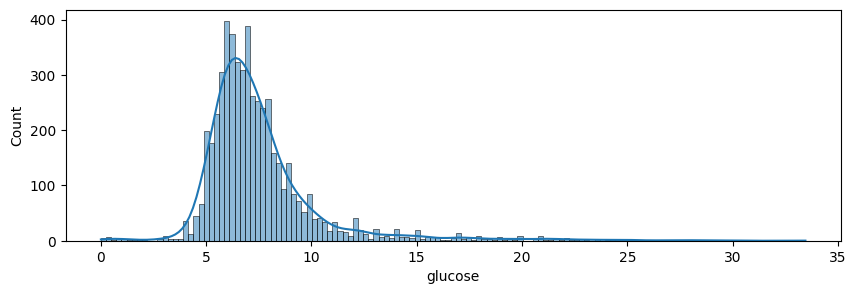

------------------------------------------------------------------------------------------


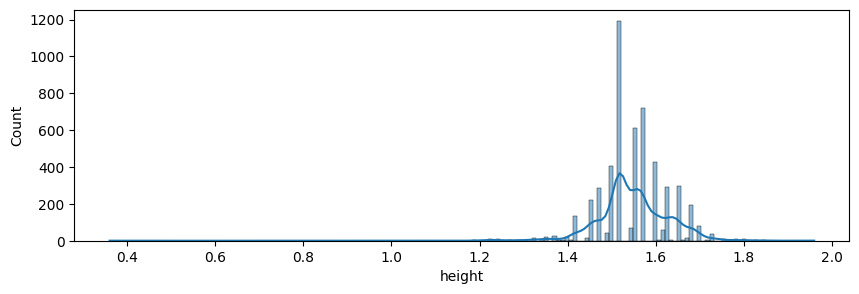

------------------------------------------------------------------------------------------


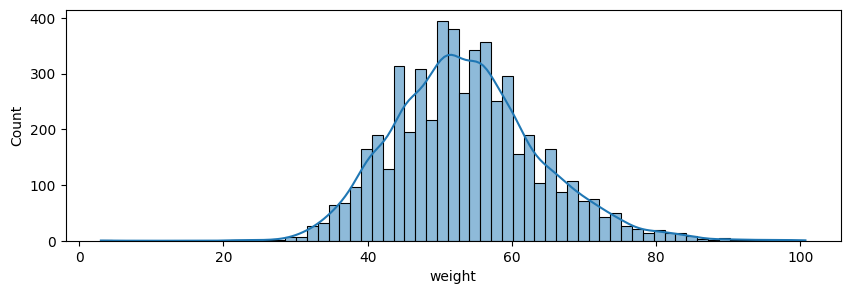

------------------------------------------------------------------------------------------


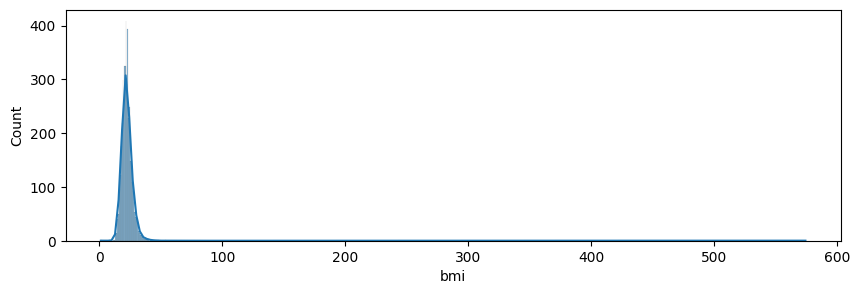

------------------------------------------------------------------------------------------


In [16]:
for col in num_cols:
  plt.figure(figsize= (10,3))
  sns.histplot(df[col], kde=True)
  plt.show()
  print('---'*30)

# Check outliers

age


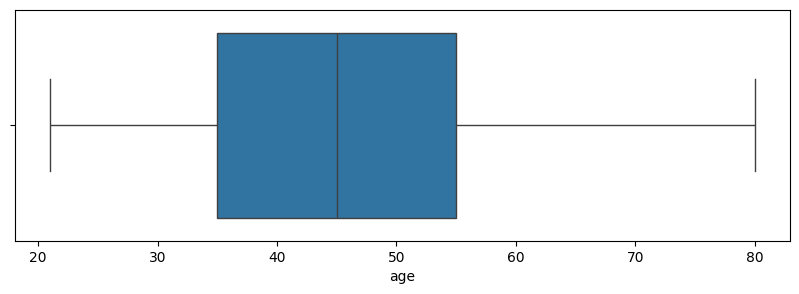

------------------------------------------------------------------------------------------
pulse_rate


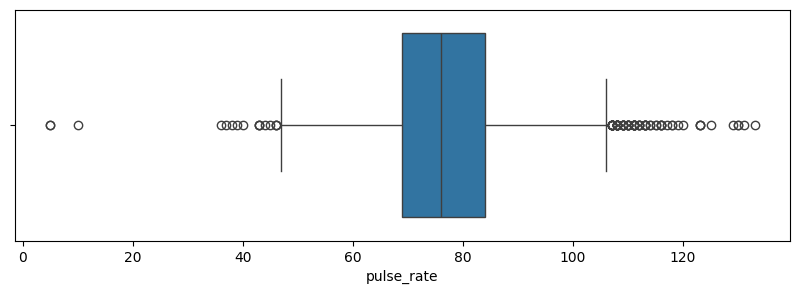

------------------------------------------------------------------------------------------
systolic_bp


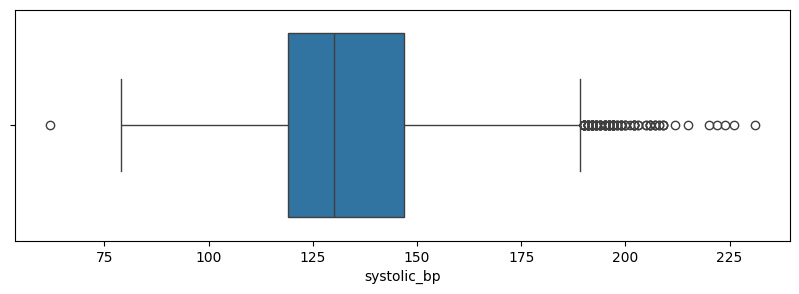

------------------------------------------------------------------------------------------
diastolic_bp


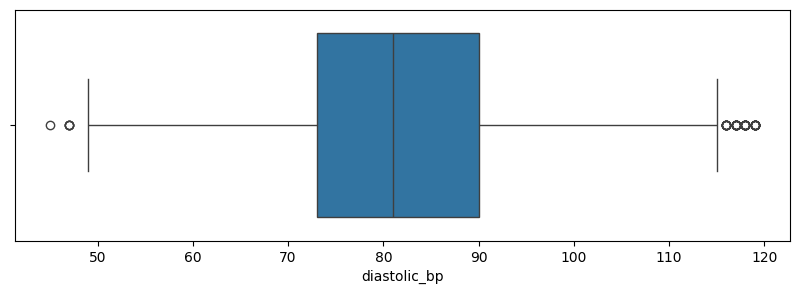

------------------------------------------------------------------------------------------
glucose


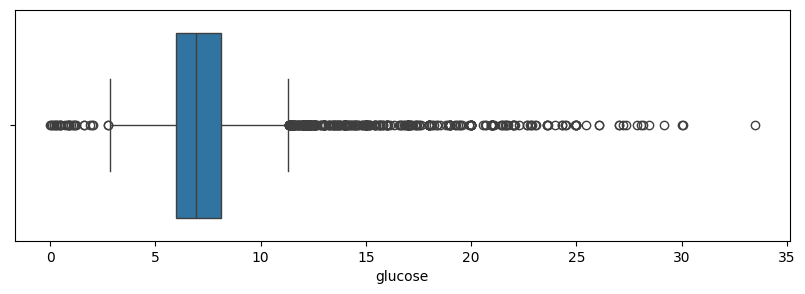

------------------------------------------------------------------------------------------
height


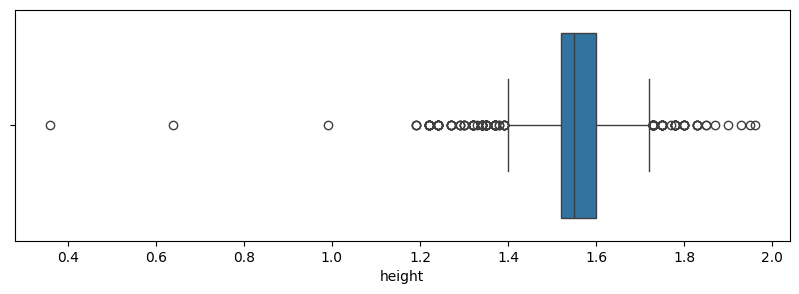

------------------------------------------------------------------------------------------
weight


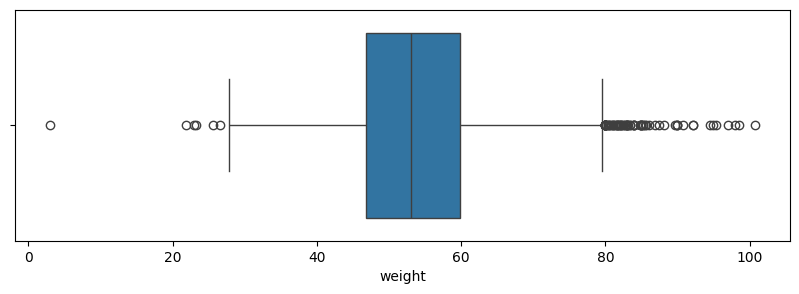

------------------------------------------------------------------------------------------
bmi


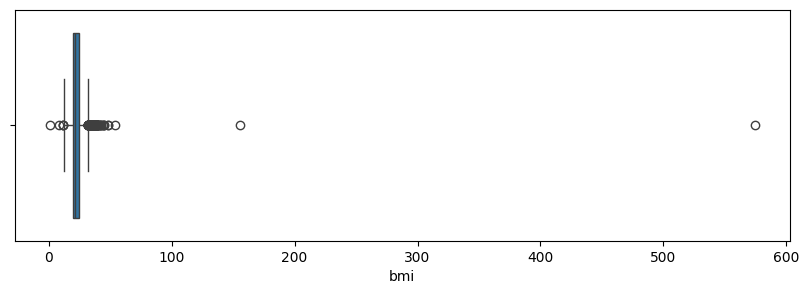

------------------------------------------------------------------------------------------


In [17]:
for col in num_cols:
  print(col)
  plt.figure(figsize=(10,3))
  sns.boxplot(df[col], orient='h')
  plt.show()
  print('---'*30)

In [18]:
num_cols = [col for col in df.select_dtypes(include=np.number).columns
            if df[col].nunique() > 2]

outlier_dict = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_dict[col] = len(outliers)

outlier_table = pd.DataFrame.from_dict(
    outlier_dict,
    orient="index",
    columns=["Outlier Count"]
)

print(outlier_table)

              Outlier Count
age                       0
pulse_rate               96
systolic_bp             113
diastolic_bp             54
glucose                 400
height                  193
weight                   79
bmi                     133


# Pre processing

In [19]:
outlier_table_before = outlier_table.copy()

In [20]:
for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = df[col].clip(lower, upper)

In [21]:
outlier_dict_after = {}

for col in num_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]
    outlier_dict_after[col] = len(outliers)

outlier_table_after = pd.DataFrame.from_dict(
    outlier_dict_after,
    orient="index",
    columns=["Outlier Count"]
)

print(outlier_table_after)

              Outlier Count
age                       0
pulse_rate                0
systolic_bp               0
diastolic_bp              0
glucose                   0
height                    0
weight                    0
bmi                       0


age


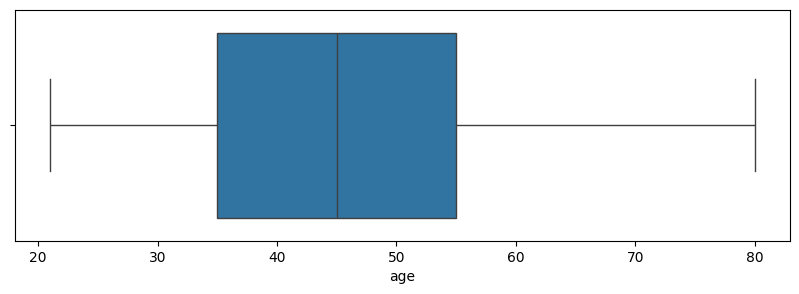

------------------------------------------------------------------------------------------
pulse_rate


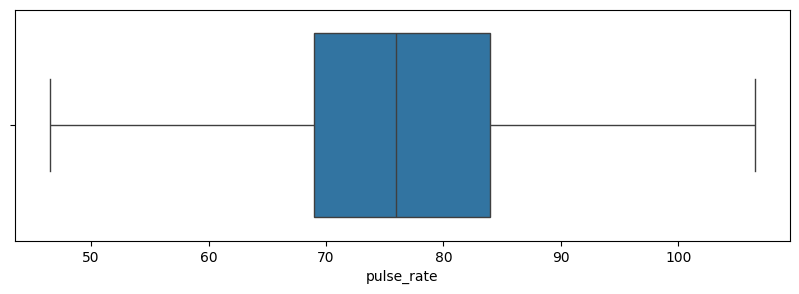

------------------------------------------------------------------------------------------
systolic_bp


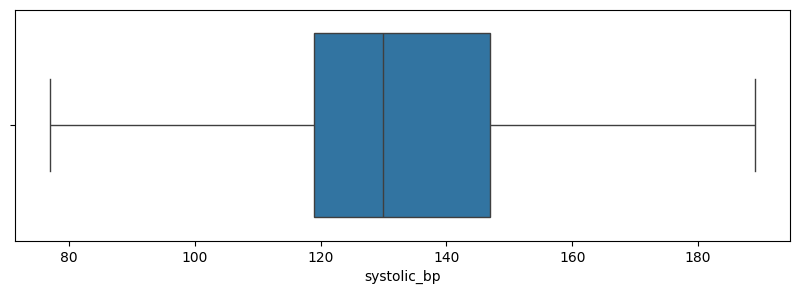

------------------------------------------------------------------------------------------
diastolic_bp


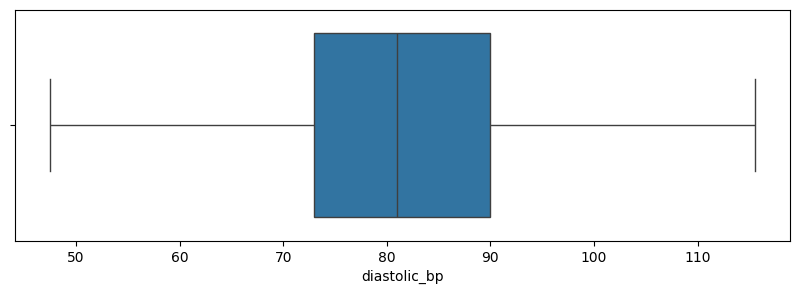

------------------------------------------------------------------------------------------
glucose


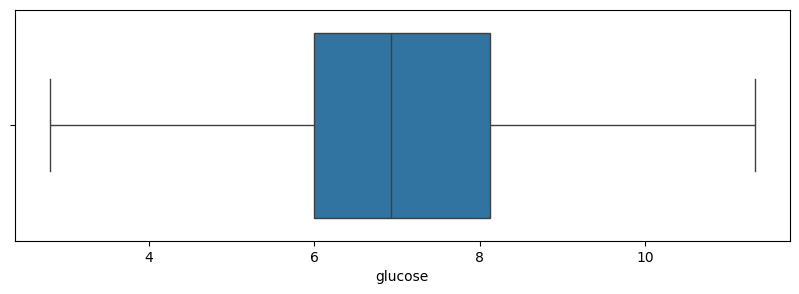

------------------------------------------------------------------------------------------
height


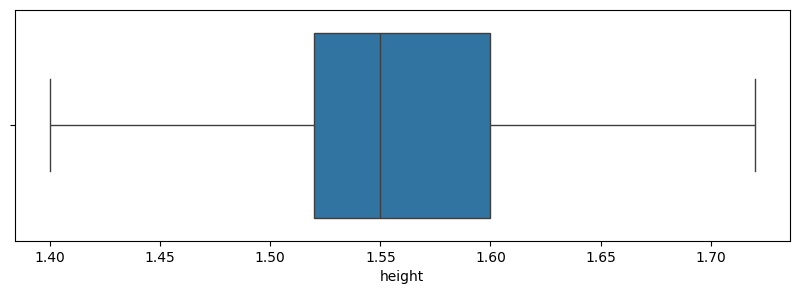

------------------------------------------------------------------------------------------
weight


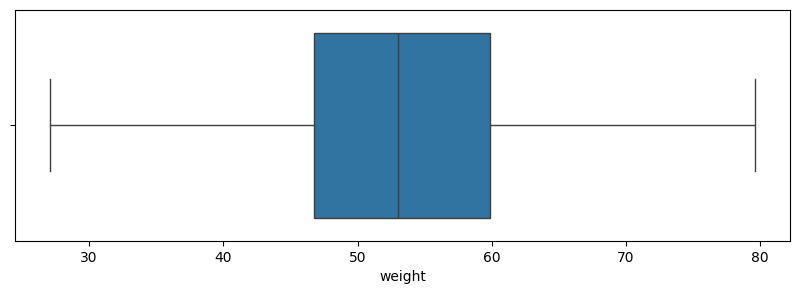

------------------------------------------------------------------------------------------
bmi


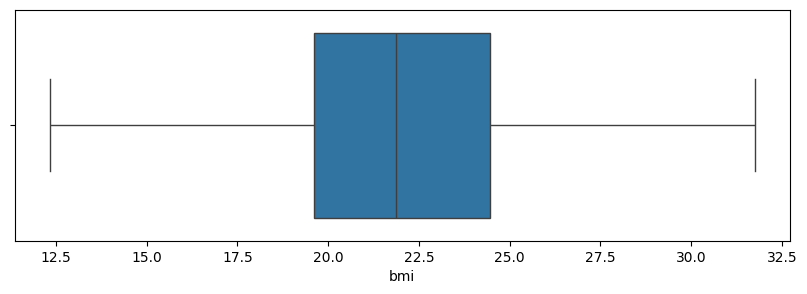

------------------------------------------------------------------------------------------


In [22]:
for col in num_cols:
  print(col)
  plt.figure(figsize=(10,3))
  sns.boxplot(df[col], orient='h')
  plt.show()
  print('---'*30)

## Encoding

In [23]:
df['gender'] = df['gender'].map({'Male': 0, 'Female': 1})
df['diabetic'] = df['diabetic'].map({'No': 0, 'Yes': 1})

In [24]:
df.head()

,age,gender,pulse_rate,systolic_bp,diastolic_bp,glucose,height,weight,bmi,family_diabetes,hypertensive,family_hypertension,cardiovascular_disease,stroke,diabetic
0,42,1,66.0,110,73.0,5.88,1.65,70.2,25.75,False,False,False,False,False,0
1,35,1,60.0,125,68.0,5.71,1.47,42.5,19.58,False,False,False,False,False,0
2,62,1,57.0,127,74.0,6.85,1.52,47.0,20.24,False,False,False,False,False,0
3,73,0,55.0,189,112.0,6.28,1.63,57.4,21.72,False,False,False,False,False,0
4,68,1,71.0,150,81.0,5.71,1.42,36.0,17.79,False,False,False,False,False,0


# Correlation analysis


Correlation with Target:
hypertensive              0.357435
glucose                   0.245527
diastolic_bp              0.155778
systolic_bp               0.155502
weight                    0.111205
bmi                       0.100597
cardiovascular_disease    0.095241
age                       0.090175
pulse_rate                0.049572
height                    0.038959
stroke                    0.033902
family_hypertension      -0.014973
family_diabetes          -0.021551
gender                   -0.024828
Name: diabetic, dtype: float64

Top 5 Features:
hypertensive    0.357435
glucose         0.245527
diastolic_bp    0.155778
systolic_bp     0.155502
weight          0.111205
Name: diabetic, dtype: float64


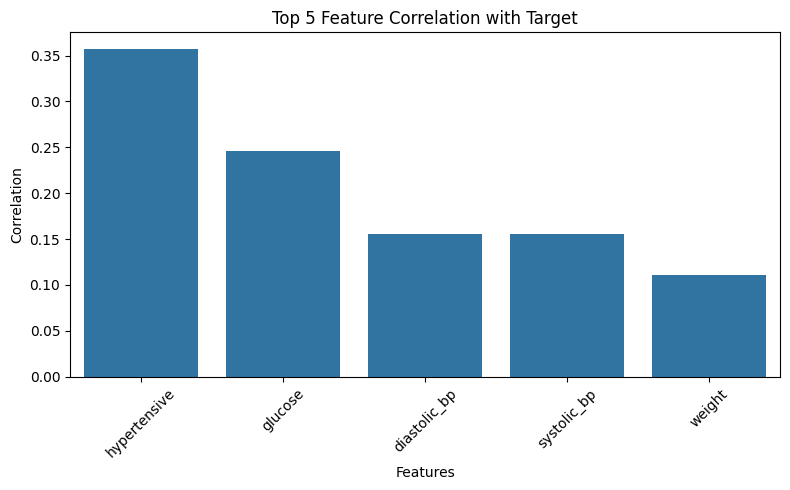

In [25]:
# Make sure only numeric columns are used #Pearson Correlation
corr = df.corr(numeric_only=True)

# Check if target exists
target = 'diabetic'  # adjust if needed

# If target is still object, encode first
if df[target].dtype == 'object':
    df[target] = df[target].map({'No': 0, 'Yes': 1})

# Recompute correlation after encoding
corr = df.corr(numeric_only=True)

# Get correlation with target
target_corr = corr[target].drop(target).sort_values(ascending=False)

print("\nCorrelation with Target:")
print(target_corr)

# Select top 5 features
top_features = target_corr.abs().sort_values(ascending=False).head(5)

print("\nTop 5 Features:")
print(top_features)

# Plot
plt.figure(figsize=(8,5))
sns.barplot(x=top_features.index, y=top_features.values)

plt.title("Top 5 Feature Correlation with Target")
plt.xlabel("Features")
plt.ylabel("Correlation")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Feature Selection

In [26]:
from sklearn.ensemble import RandomForestClassifier

X = df.drop('diabetic', axis=1)
y = df['diabetic']

model = RandomForestClassifier()
model.fit(X, y)

importances = pd.Series(model.feature_importances_, index=X.columns)
print(importances.sort_values(ascending=False))

glucose                   0.189023
bmi                       0.113177
systolic_bp               0.106469
diastolic_bp              0.100085
weight                    0.099940
pulse_rate                0.097500
hypertensive              0.097119
age                       0.091898
height                    0.072730
gender                    0.015380
cardiovascular_disease    0.008202
family_hypertension       0.003901
family_diabetes           0.002809
stroke                    0.001767
dtype: float64


In [27]:
from sklearn.linear_model import LogisticRegression
import numpy as np

# L1 Logistic Regression
l1_model = LogisticRegression(penalty='l1', solver='liblinear', max_iter=1000)
l1_model.fit(X, y)

# Ambil koefisien
coef = pd.Series(l1_model.coef_[0], index=X.columns)

# Tampilkan fitur penting (tidak nol)
selected_l1 = coef[coef != 0].sort_values(ascending=False)
print("Selected features (L1):")
print(selected_l1)

Selected features (L1):
hypertensive              2.243951
cardiovascular_disease    0.560704
glucose                   0.424685
weight                    0.048379
diastolic_bp              0.020493
pulse_rate                0.011535
age                       0.005134
systolic_bp              -0.001682
bmi                      -0.058052
stroke                   -0.094174
gender                   -0.288044
family_diabetes          -0.396020
height                   -2.359438
dtype: float64


In [28]:
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier

# Model untuk RFE nya random forest
rfe_model = RandomForestClassifier(random_state=42)

# Pilih jumlah fitur (misalnya 5 dulu)
rfe = RFE(estimator=rfe_model, n_features_to_select=5)

rfe.fit(X, y)

# Ambil fitur terpilih
selected_rfe = X.columns[rfe.support_]
print("Selected features (RFE):")
print(selected_rfe)

Selected features (RFE):
Index(['pulse_rate', 'systolic_bp', 'glucose', 'weight', 'bmi'], dtype='object')


In [29]:
print("Random Forest Top Features:")
print(importances.sort_values(ascending=False))

print("\nL1 Selected Features:")
print(selected_l1.sort_values(ascending=False))

print("\nRFE Selected Features:")
print(selected_rfe.sort_values(ascending=False))

Random Forest Top Features:
glucose                   0.189023
bmi                       0.113177
systolic_bp               0.106469
diastolic_bp              0.100085
weight                    0.099940
pulse_rate                0.097500
hypertensive              0.097119
age                       0.091898
height                    0.072730
gender                    0.015380
cardiovascular_disease    0.008202
family_hypertension       0.003901
family_diabetes           0.002809
stroke                    0.001767
dtype: float64

L1 Selected Features:
hypertensive              2.243951
cardiovascular_disease    0.560704
glucose                   0.424685
weight                    0.048379
diastolic_bp              0.020493
pulse_rate                0.011535
age                       0.005134
systolic_bp              -0.001682
bmi                      -0.058052
stroke                   -0.094174
gender                   -0.288044
family_diabetes          -0.396020
height                  

In [30]:
# Weighted Voting (Vote + Correlation)
import pandas as pd
from collections import Counter

# Siapin set dari metode correlation analysis
set_corr = set(top_features.index)  # top from correlation
set_rf   = set(importances.sort_values(ascending=False).head(5).index)
set_l1   = set(selected_l1.index)
set_rfe  = set(selected_rfe)

# Hitung votenya
all_features = list(set_corr) + list(set_rf) + list(set_l1) + list(set_rfe)
counts = Counter(all_features)

vote_score = pd.Series(counts)

# Normalisasi
corr_score = target_corr.abs()
corr_score = corr_score / corr_score.max()

# Align index
vote_score = vote_score.reindex(X.columns, fill_value=0)
corr_score = corr_score.reindex(X.columns, fill_value=0)

# Rumus final weighted score
final_score = vote_score * corr_score

# Ranking
final_ranking = final_score.sort_values(ascending=False)

# Normalisasi RF importance
rf_score = importances / importances.max()
rf_score = rf_score.reindex(X.columns, fill_value=0)

# Combine all
final_score = (vote_score * corr_score) + rf_score

final_ranking = final_score.sort_values(ascending=False)

print("Final Feature Ranking (Vote × Correlation):")
print(final_ranking)

Final Feature Ranking (Vote × Correlation):
glucose                   3.747660
hypertensive              2.513796
systolic_bp               2.303463
diastolic_bp              1.836955
weight                    1.773192
bmi                       1.443068
pulse_rate                0.793187
age                       0.738457
height                    0.493765
cardiovascular_disease    0.309848
gender                    0.150827
stroke                    0.104198
family_diabetes           0.075152
family_hypertension       0.020640
dtype: float64


In [31]:
top5  = final_ranking.head(5).index.tolist()
top7  = final_ranking.head(7).index.tolist()
top10 = final_ranking.head(10).index.tolist()
top15 = final_ranking.head(15).index.tolist()

In [32]:
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier

def evaluate(features):
    model = RandomForestClassifier(random_state=42)
    return cross_val_score(model, X[features], y, cv=5).mean()

print("Top 5:", evaluate(top5))
print("Top 7:", evaluate(top7))
print("Top 10:", evaluate(top10))
print("Top 15:", evaluate(top15))

Top 5: 0.9402422950426808
Top 7: 0.9417554765869092
Top 10: 0.9436460145970781
Top 15: 0.9419446913456604


In [33]:
best_feature = top7

# Split Data

In [34]:
best_feature = top7

In [35]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from imblearn.over_sampling import (
    RandomOverSampler,
    BorderlineSMOTE
)

# ============================================
# DATA AWAL (SEMUA FITUR)
# ============================================

X_full = X
y_full = y

# ============================================
# SPLIT DATA
# ============================================

# 70% Train
# 10% Validation
# 20% Test

X_train_full, X_temp_full, y_train, y_temp = train_test_split(
    X_full,
    y_full,
    test_size=0.3,
    stratify=y_full,
    random_state=42
)

X_val_full, X_test_full, y_val, y_test = train_test_split(
    X_temp_full,
    y_temp,
    test_size=2/3,
    stratify=y_temp,
    random_state=42
)

# ============================================
# SCALING
# ============================================

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train_full)
X_val_scaled = scaler.transform(X_val_full)
X_test_scaled = scaler.transform(X_test_full)

# kembali menjadi dataframe
X_train_scaled = pd.DataFrame(
    X_train_scaled,
    columns=X_train_full.columns
)

X_val_scaled = pd.DataFrame(
    X_val_scaled,
    columns=X_val_full.columns
)

X_test_scaled = pd.DataFrame(
    X_test_scaled,
    columns=X_test_full.columns
)

# ============================================
# RANDOM OVERSAMPLER
# ============================================

ros = RandomOverSampler(
    sampling_strategy=0.2,
    random_state=42
)

X_ros, y_ros = ros.fit_resample(
    X_train_scaled,
    y_train
)

# ============================================
# BORDERLINE SMOTE
# ============================================

bsmote = BorderlineSMOTE(
    sampling_strategy=0.3,
    random_state=42
)

X_train_resampled, y_train_resampled = bsmote.fit_resample(
    X_ros,
    y_ros
)

# ============================================
# DATA TANPA FEATURE SELECTION
# ============================================

X_train_no_fs = X_train_resampled
X_val_no_fs = X_val_scaled
X_test_no_fs = X_test_scaled

# ============================================
# FEATURE SELECTION
# ============================================

X_train_selected = X_train_resampled[best_feature]

X_val_selected = X_val_scaled[best_feature]

X_test_selected = X_test_scaled[best_feature]

# ============================================
# CEK DISTRIBUSI KELAS
# ============================================

print("=== CLASS DISTRIBUTION AFTER SAMPLING ===")
print(pd.Series(y_train_resampled).value_counts())

# ============================================
# CEK SHAPE
# ============================================

print("\n=== TANPA FEATURE SELECTION ===")
print(X_train_no_fs.shape)

print("\n=== DENGAN FEATURE SELECTION ===")
print(X_train_selected.shape)

=== CLASS DISTRIBUTION AFTER SAMPLING ===
diabetic
0    3462
1    1038
Name: count, dtype: int64

=== TANPA FEATURE SELECTION ===
(4500, 14)

=== DENGAN FEATURE SELECTION ===
(4500, 7)


In [36]:
total_samples = len(X_full)

train_count = len(X_train_full)
val_count = len(X_val_full)
test_count = len(X_test_full)

train_proportion = train_count / total_samples
val_proportion = val_count / total_samples
test_proportion = test_count / total_samples

print(f"Train set: {train_count} samples ({train_proportion:.2%})")
print(f"Validation set: {val_count} samples ({val_proportion:.2%})")
print(f"Test set: {test_count} samples ({test_proportion:.2%})")

Train set: 3701 samples (69.99%)
Validation set: 529 samples (10.00%)
Test set: 1058 samples (20.01%)


# Modeling

## Without Feature Selection

In [37]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ============================================
# MODELS - NO FEATURE SELECTION
# ============================================

rf_base = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    min_samples_leaf=50,
    random_state=42
)

lr_base = LogisticRegression(
    C=0.01,
    max_iter=1000,
    class_weight='balanced'
)

knn_base = KNeighborsClassifier(
    n_neighbors=100
)

xgb_base = XGBClassifier(
    n_estimators=50,
    max_depth=2,
    reg_alpha=15,
    reg_lambda=15,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

stacking_full = StackingClassifier(
    estimators=[
        ('rf', rf_base),
        ('lr', lr_base),
        ('knn', knn_base),
        ('xgb', xgb_base)
    ],
    final_estimator=LogisticRegression(
    C=0.1,
    class_weight='balanced',
    max_iter=1000
  ),
    passthrough=True
)

models = {
    'Random Forest': rf_base,
    'Logistic Regression': lr_base,
    'KNN': knn_base,
    'XGBoost': xgb_base,
    'Ensemble Stacking': stacking_full
}

# ============================================
# EVALUATION
# ============================================

results = []

for name, model in models.items():


    # TRAIN
    model.fit(
        X_train_resampled,
        y_train_resampled
    )

    # TRAIN PREDICTION
    train_pred = model.predict(X_train_resampled)

    train_acc = accuracy_score(
        y_train_resampled,
        train_pred
    )

    train_precision = precision_score(
        y_train_resampled,
        train_pred
    )

    train_recall = recall_score(
        y_train_resampled,
        train_pred
    )

    train_f1 = f1_score(
        y_train_resampled,
        train_pred
    )

    # ============================================
    # THRESHOLD TUNING USING VALIDATION SET
    # ============================================

    val_prob = model.predict_proba(X_val_scaled)[:,1]

    best_threshold = 0.5
    best_f1 = 0

    min_required_recall = 0.60

    thresholds = np.arange(0.1, 0.91, 0.01)

    for threshold in thresholds:

        val_pred_temp = (
            val_prob >= threshold
        ).astype(int)

        val_recall_temp = recall_score(
            y_val,
            val_pred_temp,
            zero_division=0
        )

        val_f1_temp = f1_score(
            y_val,
            val_pred_temp,
            zero_division=0
        )

        # pilih threshold jika recall memenuhi syarat
        if val_recall_temp >= min_required_recall:

            if val_f1_temp > best_f1:

                best_f1 = val_f1_temp
                best_threshold = threshold

# ============================================
# TEST PREDICTION
# ============================================

    test_prob = model.predict_proba(
        X_test_scaled
    )[:,1]

    test_pred = (
        test_prob >= best_threshold
    ).astype(int)

    test_acc = accuracy_score(
        y_test,
        test_pred
    )

    test_precision = precision_score(
        y_test,
        test_pred
    )

    test_recall = recall_score(
        y_test,
        test_pred
    )

    test_f1 = f1_score(
        y_test,
        test_pred
    )

    test_auc = roc_auc_score(
        y_test,
        test_prob
    )

    f1_gap = abs(
        train_f1 - test_f1
    )

    # VALIDATION
    val_pred = model.predict(X_val_scaled)

    val_prob = model.predict_proba(X_val_scaled)[:,1]

    val_acc = accuracy_score(y_val, val_pred)

    val_precision = precision_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_recall = recall_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_f1 = f1_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_auc = roc_auc_score(
        y_val,
        val_prob
    )

    print(f"\n{name}")
    print("Best Threshold :", round(best_threshold,2))
    print("Validation F1  :", round(best_f1,4))

    results.append({
        'Best Threshold': round(best_threshold,2),

        'Model': name,

        'Train Accuracy': round(train_acc,4),
        'Train Precision': round(train_precision,4),
        'Train Recall': round(train_recall,4),
        'Train F1': round(train_f1,4),

        'Test Accuracy': round(test_acc,4),
        'Test Precision': round(test_precision,4),
        'Test Recall': round(test_recall,4),
        'Test F1': round(test_f1,4),
        'Test ROC-AUC': round(test_auc,4),

        'Val Accuracy': round(val_acc,4),
        'Val Precision': round(val_precision,4),
        'Val Recall': round(val_recall,4),
        'Val F1': round(val_f1,4),
        'Val ROC-AUC': round(val_auc,4),

        'F1 Gap': round(f1_gap,4)
    })

# ============================================
# RESULT TABLE
# ============================================

comparison_full_df = pd.DataFrame(results)

print("\n")
print("="*100)
print("FULL FEATURE MODEL COMPARISON")
print("="*100)

display(
    comparison_full_df.sort_values(
        by='Test F1',
        ascending=False
    )
)


Random Forest
Best Threshold : 0.39
Validation F1  : 0.4646

Logistic Regression
Best Threshold : 0.64
Validation F1  : 0.4545

KNN
Best Threshold : 0.4
Validation F1  : 0.4468

XGBoost
Best Threshold : 0.47
Validation F1  : 0.4828

Ensemble Stacking
Best Threshold : 0.72
Validation F1  : 0.4731


FULL FEATURE MODEL COMPARISON


,Best Threshold,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,F1 Gap
4,0.72,Ensemble Stacking,0.8140,0.5700,0.7881,0.6615,0.8819,0.2910,0.5652,0.3842,0.8536,0.8166,0.2261,0.7647,0.3490,0.8687,0.2773
0,0.39,Random Forest,0.8298,0.8178,0.3372,0.4775,0.8696,0.2587,0.5362,0.3491,0.8470,0.9319,0.4583,0.3235,0.3793,0.8755,0.1284
3,0.47,XGBoost,0.8222,0.7288,0.3651,0.4865,0.8894,0.2818,0.4493,0.3464,0.8448,0.9187,0.3846,0.4412,0.4110,0.8682,0.1402
2,0.40,KNN,0.8264,0.7182,0.4075,0.5200,0.8762,0.2615,0.4928,0.3417,0.8400,0.9187,0.3953,0.5000,0.4416,0.8454,0.1783
1,0.64,Logistic Regression,0.7829,0.5207,0.7399,0.6112,0.8422,0.2216,0.5652,0.3184,0.8333,0.8015,0.2066,0.7353,0.3226,0.8598,0.2929


## With Feature Selection

In [38]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ============================================
# MODELS - NO FEATURE SELECTION
# ============================================

rf_base = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    min_samples_leaf=50,
    random_state=42
)

lr_base = LogisticRegression(
    C=0.01,
    max_iter=1000,
    class_weight='balanced'
)

knn_base = KNeighborsClassifier(
    n_neighbors=100
)

xgb_base = XGBClassifier(
    n_estimators=50,
    max_depth=2,
    reg_alpha=15,
    reg_lambda=15,
    learning_rate=0.05,
    random_state=42,
    eval_metric='logloss'
)

stacking_full = StackingClassifier(
    estimators=[
        ('rf', rf_base),
        ('lr', lr_base),
        ('knn', knn_base),
        ('xgb', xgb_base)
    ],
    final_estimator=LogisticRegression(
    C=0.1,
    class_weight='balanced',
    max_iter=1000
  ),
    passthrough=True
)

models = {
    'Random Forest': rf_base,
    'Logistic Regression': lr_base,
    'KNN': knn_base,
    'XGBoost': xgb_base,
    'Ensemble Stacking': stacking_full
}

# ============================================
# EVALUATION
# ============================================

results = []

for name, model in models.items():

    # TRAIN
    model.fit(
        X_train_selected,
        y_train_resampled
    )

    # TRAIN PREDICTION
    train_pred = model.predict(
        X_train_selected
    )
    train_acc = accuracy_score(
        y_train_resampled,
        train_pred
    )

    train_precision = precision_score(
        y_train_resampled,
        train_pred
    )

    train_recall = recall_score(
        y_train_resampled,
        train_pred
    )

    train_f1 = f1_score(
        y_train_resampled,
        train_pred
    )

   # ============================================
    # THRESHOLD TUNING USING VALIDATION SET
    # ============================================

    val_prob = model.predict_proba(X_val_selected)[:,1]

    best_threshold = 0.5
    best_f1 = 0

    min_required_recall = 0.60

    thresholds = np.arange(0.1, 0.91, 0.01)

    for threshold in thresholds:

        val_pred_temp = (
            val_prob >= threshold
        ).astype(int)

        val_recall_temp = recall_score(
            y_val,
            val_pred_temp,
            zero_division=0
        )

        val_f1_temp = f1_score(
            y_val,
            val_pred_temp,
            zero_division=0
        )

        # pilih threshold jika recall memenuhi syarat
        if val_recall_temp >= min_required_recall:

            if val_f1_temp > best_f1:

                best_f1 = val_f1_temp
                best_threshold = threshold

# ============================================
# TEST PREDICTION
# ============================================

    test_prob = model.predict_proba(
        X_test_selected
    )[:,1]

    test_pred = (
        test_prob >= best_threshold
    ).astype(int)

    test_acc = accuracy_score(
        y_test,
        test_pred
    )

    test_precision = precision_score(
        y_test,
        test_pred
    )

    test_recall = recall_score(
        y_test,
        test_pred
    )

    test_f1 = f1_score(
        y_test,
        test_pred
    )

    test_auc = roc_auc_score(
        y_test,
        test_prob
    )

    f1_gap = abs(
        train_f1 - test_f1
    )

    # VALIDATION
    val_pred = model.predict(X_val_selected)

    val_prob = model.predict_proba(X_val_selected)[:,1]

    val_acc = accuracy_score(y_val, val_pred)

    val_precision = precision_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_recall = recall_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_f1 = f1_score(
        y_val,
        val_pred,
        zero_division=0
    )

    val_auc = roc_auc_score(
        y_val,
        val_prob
    )

    print(f"\n{name}")
    print("Best Threshold :", round(best_threshold,2))
    print("Validation F1  :", round(best_f1,4))

    results.append({
        'Best Threshold': round(best_threshold,2),

        'Model': name,

        'Train Accuracy': round(train_acc,4),
        'Train Precision': round(train_precision,4),
        'Train Recall': round(train_recall,4),
        'Train F1': round(train_f1,4),

        'Test Accuracy': round(test_acc,4),
        'Test Precision': round(test_precision,4),
        'Test Recall': round(test_recall,4),
        'Test F1': round(test_f1,4),
        'Test ROC-AUC': round(test_auc,4),

        'Val Accuracy': round(val_acc,4),
        'Val Precision': round(val_precision,4),
        'Val Recall': round(val_recall,4),
        'Val F1': round(val_f1,4),
        'Val ROC-AUC': round(val_auc,4),

        'F1 Gap': round(f1_gap,4)
    })

# ============================================
# RESULT TABLE
# ============================================

comparison_full_df = pd.DataFrame(results)

print("\n")
print("="*100)
print("FULL FEATURE MODEL COMPARISON")
print("="*100)

display(
    comparison_full_df.sort_values(
        by='Test F1',
        ascending=False
    )
)


Random Forest
Best Threshold : 0.38
Validation F1  : 0.4386

Logistic Regression
Best Threshold : 0.67
Validation F1  : 0.4466

KNN
Best Threshold : 0.45
Validation F1  : 0.4421

XGBoost
Best Threshold : 0.45
Validation F1  : 0.4632

Ensemble Stacking
Best Threshold : 0.76
Validation F1  : 0.4719


FULL FEATURE MODEL COMPARISON


,Best Threshold,Model,Train Accuracy,Train Precision,Train Recall,Train F1,Test Accuracy,Test Precision,Test Recall,Test F1,Test ROC-AUC,Val Accuracy,Val Precision,Val Recall,Val F1,Val ROC-AUC,F1 Gap
4,0.76,Ensemble Stacking,0.8058,0.5595,0.7428,0.6382,0.8885,0.2975,0.5217,0.3789,0.8502,0.8223,0.2273,0.7353,0.3472,0.8607,0.2593
0,0.38,Random Forest,0.8387,0.7826,0.4162,0.5434,0.8592,0.2590,0.6232,0.3660,0.8452,0.9187,0.3636,0.3529,0.3582,0.8598,0.1774
3,0.45,XGBoost,0.8211,0.7363,0.3497,0.4742,0.8752,0.2701,0.5362,0.3592,0.8407,0.9225,0.4000,0.4118,0.4058,0.8613,0.1150
2,0.45,KNN,0.8200,0.6733,0.4268,0.5224,0.8752,0.2632,0.5072,0.3465,0.8355,0.9093,0.3600,0.5294,0.4286,0.8371,0.1759
1,0.67,Logistic Regression,0.7816,0.5191,0.7197,0.6031,0.8554,0.2273,0.5072,0.3139,0.8299,0.8110,0.2155,0.7353,0.3333,0.8564,0.2892


# Visualization

## Feature Importance

### XGBoost

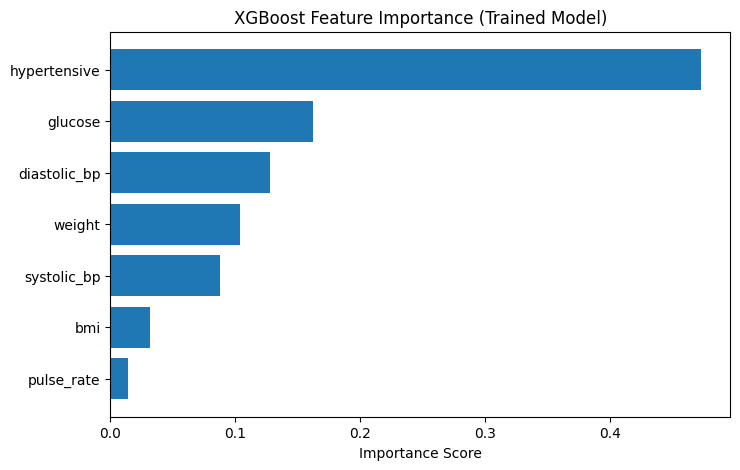

In [39]:
# Access the trained XGBoost model from the 'models' dictionary created in previous cells
trained_xgb = models['XGBoost']

# Get importance
importance = trained_xgb.feature_importances_

# Create dataframe
feat_imp = pd.DataFrame({
    'Feature': X_train_selected.columns,
    'Importance': importance
}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(8,5))
plt.barh(feat_imp['Feature'], feat_imp['Importance'])
plt.gca().invert_yaxis()
plt.title('XGBoost Feature Importance (Trained Model)')
plt.xlabel('Importance Score')
plt.show()

### Random Forest

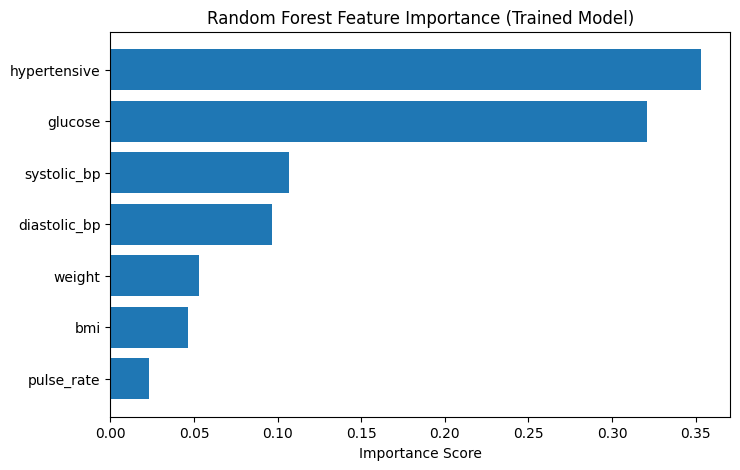

In [40]:
# Access the trained Random Forest model
trained_rf = models['Random Forest']

# Get importance
importance_rf = trained_rf.feature_importances_

# Create dataframe
feat_imp_rf = pd.DataFrame({
    'Feature': X_train_selected.columns,
    'Importance': importance_rf
}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(8,5))
plt.barh(feat_imp_rf['Feature'], feat_imp_rf['Importance'])
plt.gca().invert_yaxis()
plt.title('Random Forest Feature Importance (Trained Model)')
plt.xlabel('Importance Score')
plt.show()

### Logistic Regression (Koefisien)

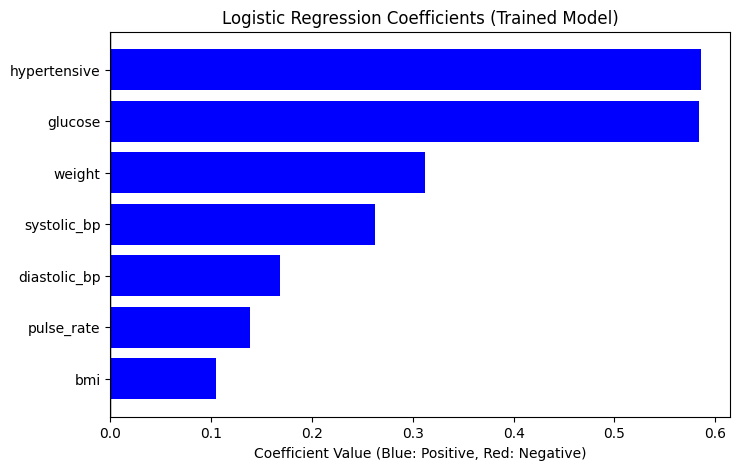

In [41]:
# Access the trained Logistic Regression model
trained_lr = models['Logistic Regression']

# Get coefficients
coefficients = trained_lr.coef_[0]

# Create dataframe
lr_importance_df = pd.DataFrame({
    'Feature': X_train_selected.columns,
    'Coefficient': coefficients
})

# Absolute importance for sorting
lr_importance_df['Abs_Importance'] = lr_importance_df['Coefficient'].abs()
lr_importance_df = lr_importance_df.sort_values(by='Abs_Importance', ascending=False)

# Plot
plt.figure(figsize=(8,5))
colors = ['red' if x < 0 else 'blue' for x in lr_importance_df['Coefficient']]
plt.barh(lr_importance_df['Feature'], lr_importance_df['Coefficient'], color=colors)
plt.gca().invert_yaxis()
plt.axvline(x=0, color='black', linestyle='-', linewidth=1)
plt.title('Logistic Regression Coefficients (Trained Model)')
plt.xlabel('Coefficient Value (Blue: Positive, Red: Negative)')
plt.show()

## Permutation Importance

### Ensemble stacking

/tmp/ipykernel_2846/438482724.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=perm_importance_df, x='Importance', y='Feature', palette='viridis')


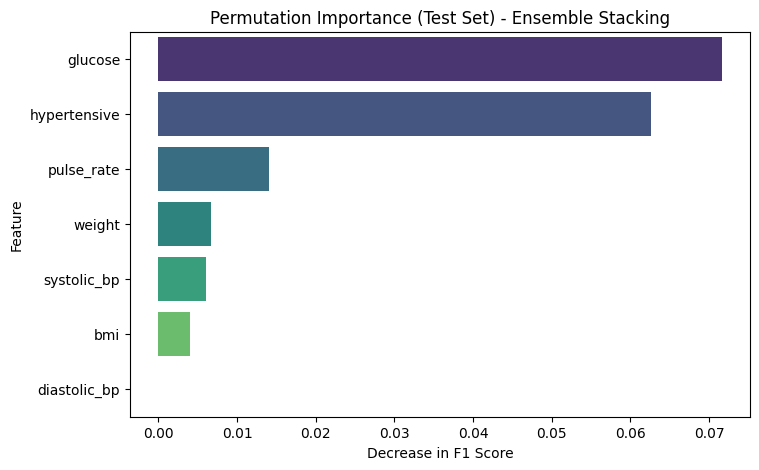

In [42]:
from sklearn.inspection import permutation_importance

# ==============================
# PERMUTATION IMPORTANCE
# ENSEMBLE STACKING
# ==============================

# Use the trained stacking model from the models dictionary
stacking_model = models['Ensemble Stacking']

# Calculate permutation importance using the test set and F1 score
# We use X_test_selected because this specific model was trained on 7 features
perm_result = permutation_importance(
    stacking_model,
    X_test_selected,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='f1'
)

# Create dataframe
perm_importance_df = pd.DataFrame({
    'Feature': X_test_selected.columns,
    'Importance': perm_result.importances_mean
}).sort_values(by='Importance', ascending=False)

# ==============================
# VISUALIZATION
# ==============================

plt.figure(figsize=(8,5))
sns.barplot(data=perm_importance_df, x='Importance', y='Feature', palette='viridis')
plt.title('Permutation Importance (Test Set) - Ensemble Stacking')
plt.xlabel('Decrease in F1 Score')
plt.show()

## ROC Curve

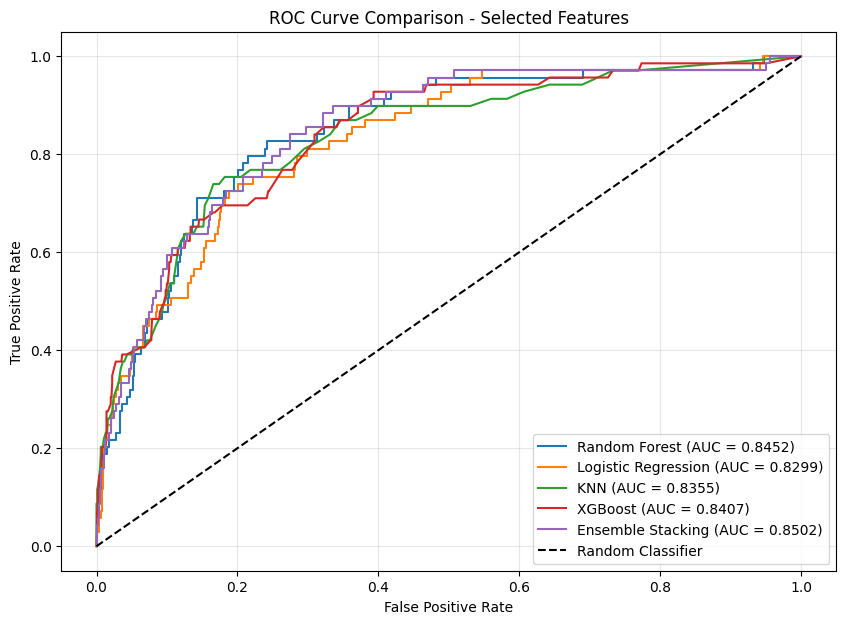

In [43]:
from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(10, 7))

# Loop through each model to plot ROC curve
for name, model in models.items():
    # Get probabilities for class 1 (Diabetic)
    # We use X_test_selected because these models were trained on the top 7 features
    proba = model.predict_proba(X_test_selected)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_score = roc_auc_score(y_test, proba)

    plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.4f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve Comparison - Selected Features')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()

## Precision-Recall Curve

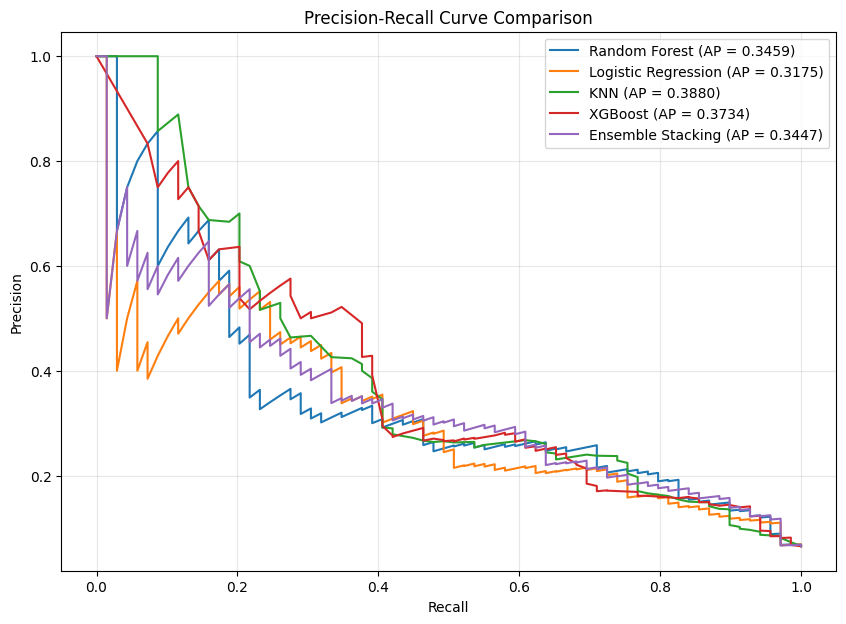

In [44]:
from sklearn.metrics import precision_recall_curve, average_precision_score

plt.figure(figsize=(10, 7))

for name, model in models.items():
    proba = model.predict_proba(X_test_selected)[:, 1]
    precision, recall, _ = precision_recall_curve(y_test, proba)
    ap_score = average_precision_score(y_test, proba)

    plt.plot(recall, precision, label=f'{name} (AP = {ap_score:.4f})')

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve Comparison')
plt.legend(loc='upper right')
plt.grid(alpha=0.3)
plt.show()

## Confusion Matrix

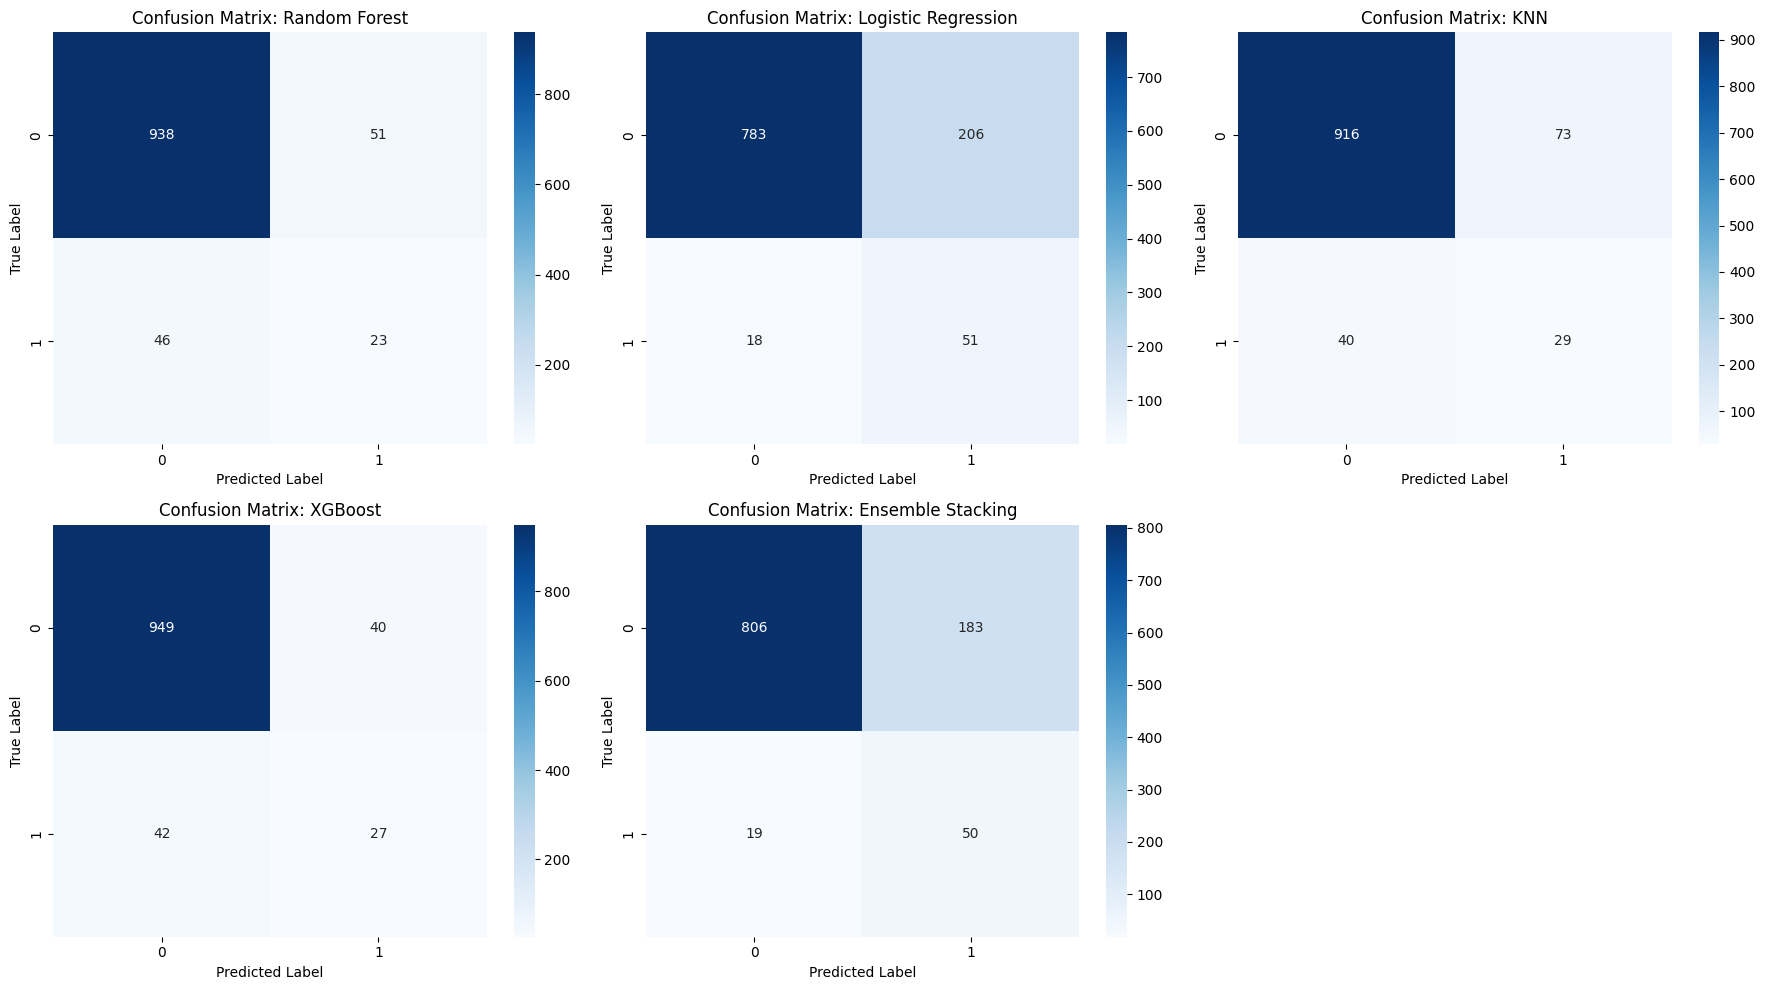

In [45]:
from sklearn.metrics import confusion_matrix

# Visualize Confusion Matrix for each model
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    pred = model.predict(X_test_selected)
    cm = confusion_matrix(y_test, pred)

    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i])
    axes[i].set_title(f'Confusion Matrix: {name}')
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('True Label')

# Hide empty subplot if any
if len(models) < len(axes):
    for j in range(len(models), len(axes)):
        axes[j].axis('off')

plt.tight_layout()
plt.show()

# Save Model

In [47]:
from google.colab import files
import joblib

# Assuming 'models' dictionary and 'Ensemble Stacking' model are available from previous cells
trained_model = models['Ensemble Stacking']

# Save the trained model to a file named 'model.pkl'
joblib.dump(trained_model, 'model.pkl')

files.download('model.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>